# Titanic: Machine Learning from Disaster

## A beginner-friendly Kaggle workshop

**Goal:** use passenger information to predict whether someone survived the Titanic disaster.

By the end, you will be able to:

1. Navigate a Kaggle Notebook and load a competition dataset.
2. Identify features, a target, training data, and test data.
3. Prepare numeric and categorical data for machine learning.
4. Compare several models fairly using validation accuracy and cross-validation.
5. Tune hyperparameters, make a Kaggle submission, and interpret the result.

This notebook is designed to be run from top to bottom. Most cells explain *why* before showing *how*. You do not need prior Python or Colab experience.

> **Important:** Kaggle's `test.csv` does not include the answers. We use a validation split from `train.csv` while learning, then use all labeled training rows to create the final submission.

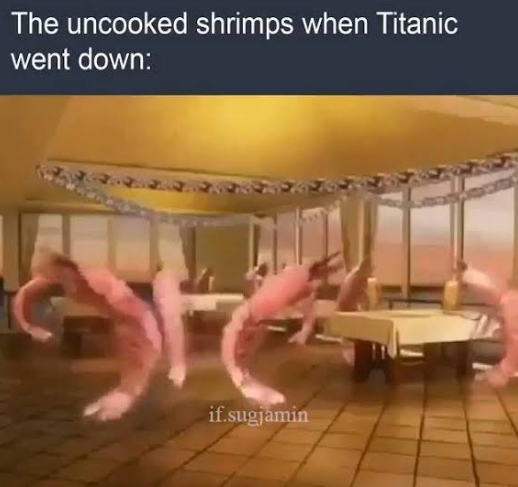

## 0. Kaggle setup

1. Open the [Titanic competition](https://www.kaggle.com/competitions/titanic).
2. Click **Join Competition** and accept the rules if Kaggle asks.
3. Open the **Code** tab and create a new notebook.
4. Paste or upload this notebook.
5. Run cells with the play button, or use **Run All**.

A notebook is a document made of **cells**. Markdown cells contain explanations; code cells contain Python. A variable created in one code cell is available to later cells, so running cells out of order can cause confusing errors.


In [ ]:
# Imports: reusable tools we will use throughout the workshop.

#KAGGLE API: KGAT_a45cdea241e91d851521e185411ff421
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

pd.set_option("display.max_columns", 30)
RANDOM_STATE = 42
print("Libraries loaded!")

### Finding the files

Kaggle normally stores competition files under `/kaggle/input/titanic/`. The fallback makes the notebook easier to try on a personal computer if `train.csv` and `test.csv` are in the same folder as the notebook.


In [ ]:
'''kaggle_folder = Path("/kaggle/input/titanic")
local_folder = Path(".")
data_folder = kaggle_folder if (kaggle_folder / "train.csv").exists() else local_folder

train_path = data_folder / "train.csv"
test_path = data_folder / "test.csv"
if not train_path.exists() or not test_path.exists():
    raise FileNotFoundError(
        "Could not find train.csv and test.csv. In Kaggle, add the Titanic competition data "
        "to the notebook, or place both files beside this notebook."
    )'''


import kagglehub
kagglehub.login()

# Download latest version
path = kagglehub.competition_download('titanic')

print("Path to competition files:", path)

train = pd.read_csv(f"{path}/train.csv")
test  = pd.read_csv(f"{path}/test.csv")

print(f"Training rows and columns: {train.shape}")
print(f"Test rows and columns:     {test.shape}")
display(train.head())

100%|██████████| 34.1k/34.1k [00:00<00:00, 20.8MB/s]

Extracting files...
Path to competition files: /root/.cache/kagglehub/competitions/titanic
Training rows and columns: (891, 12)
Test rows and columns:     (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 1. Understand the problem

A **row** represents one passenger. A **feature** is information used to make a prediction, such as `Sex` or `Pclass`. The **target** is what we want to predict: `Survived` (`0` = did not survive, `1` = survived).

`train.csv` contains the target, so it teaches the model. `test.csv` contains new passengers but hides the target; Kaggle reveals the score after we submit predictions.


In [ ]:
print("Training columns:", train.columns.tolist())
print("Test columns:    ", test.columns.tolist())
print("\nTarget counts:")
display(train["Survived"].value_counts().rename(index={0: "Did not survive", 1: "Survived"}))
print("\nMissing values in training data:")
display(train.isna().sum().sort_values(ascending=False).head(10))

Training columns: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
Test columns:     ['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Target counts:


,count
Survived,
Did not survive,549
Survived,342



Missing values in training data:


,0
Cabin,687
Age,177
Embarked,2
PassengerId,0
Name,0
Pclass,0
Survived,0
Sex,0
Parch,0
SibSp,0


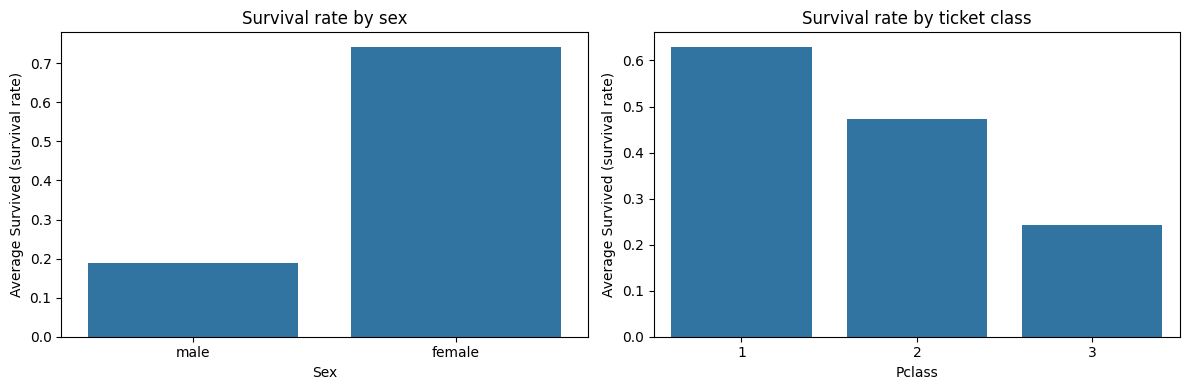

In [ ]:
# A quick look at survival rates by two important variables.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=train, x="Sex", y="Survived", ax=axes[0], errorbar=None)
axes[0].set_title("Survival rate by sex")
sns.barplot(data=train, x="Pclass", y="Survived", ax=axes[1], errorbar=None)
axes[1].set_title("Survival rate by ticket class")
for ax in axes:
    ax.set_ylabel("Average Survived (survival rate)")
plt.tight_layout()
plt.show()

### A first baseline

Before using machine learning, make a simple rule. The competition provides a useful baseline: predict that all women survive and all men do not. A baseline gives us a result to beat.


In [ ]:
gender_rule = (train["Sex"] == "female").astype(int)
print(f"Gender-rule accuracy on the labeled data: {accuracy_score(train['Survived'], gender_rule):.3f}")
print("This is a reference point, not a model trained by scikit-learn.")

Gender-rule accuracy on the labeled data: 0.787
This is a reference point, not a model trained by scikit-learn.


## 2. Prepare the data

We will start with a small, teachable set of columns:

- `Pclass`: passenger class; numeric, but also represents socioeconomic status.
- `Sex`: a categorical value such as `male` or `female`.
- `Age`, `SibSp`, `Parch`, `Fare`: numeric values.
- `Embarked`: a categorical port code.

We leave out `PassengerId` because it is an identifier, not a meaningful passenger characteristic. We also initially leave out `Name`, `Ticket`, and `Cabin`; later we will show how feature engineering can extract useful information from them.

Two common data problems are handled automatically in our pipeline:

- **Missing numeric values** are filled with the median.
- **Categorical values** are filled with the most common category and converted to columns of 0s and 1s (one-hot encoding).

A pipeline makes sure the same preparation is applied consistently to training, validation, and test data.


In [ ]:
basic_features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
X = train[basic_features]
y = train["Survived"]
X_test = test[basic_features]

numeric_features = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
categorical_features = ["Sex", "Embarked"]

numeric_preprocessor = Pipeline([
    ("fill_missing", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
categorical_preprocessor = Pipeline([
    ("fill_missing", SimpleImputer(strategy="most_frequent")),
    ("one_hot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("numbers", numeric_preprocessor, numeric_features),
    ("categories", categorical_preprocessor, categorical_features),
])

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"Training portion:   {X_train.shape[0]} passengers")
print(f"Validation portion: {X_valid.shape[0]} passengers")

Training portion:   712 passengers
Validation portion: 179 passengers


## Why split the data?

If we measure a model on the same rows it learned from, we are mostly measuring memorization. A **validation set** is held back until after training to imitate unseen passengers. `stratify=y` keeps the same survival proportion in both portions.

We use `random_state=42` so everyone in the workshop gets the same split and can compare results.


## 3. Try several models

A model is an algorithm that learns a relationship between features and the target. Different models make different assumptions:

- **Logistic regression:** a simple, interpretable linear boundary.
- **Decision tree:** a sequence of if/then questions.
- **Random forest:** many trees whose predictions are combined.
- **Support vector machine (SVM):** finds a boundary that separates classes.
- **Neural network (MLP):** learns layers of weighted combinations using backpropagation.

The preprocessing pipeline is included inside every model, so this is an apples-to-apples comparison.


In [ ]:
models = {
    "Logistic regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision tree": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
    "Random forest": RandomForestClassifier(n_estimators=200, max_depth=6, random_state=RANDOM_STATE),
    "SVM": SVC(C=1.0, kernel="rbf", random_state=RANDOM_STATE),
    "Neural network": MLPClassifier(hidden_layer_sizes=(16,), alpha=0.001, max_iter=1000, random_state=RANDOM_STATE),
}

validation_results = []
fitted_models = {}
for name, estimator in models.items():
    pipe = Pipeline([( "prepare", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    predictions = pipe.predict(X_valid)
    score = accuracy_score(y_valid, predictions)
    validation_results.append({"Model": name, "Validation accuracy": score})
    fitted_models[name] = pipe

results = pd.DataFrame(validation_results).sort_values("Validation accuracy", ascending=False)
display(results.round(3))

,Model,Validation accuracy
2,Random forest,0.816
3,SVM,0.816
0,Logistic regression,0.804
4,Neural network,0.799
1,Decision tree,0.793


### Read the comparison carefully

The highest validation accuracy is useful, but a difference of one or two correct passengers may be random. We should check performance across several splits using **cross-validation**. This repeatedly trains on most of the labeled data and validates on the remaining fold.


In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, estimator in models.items():
    pipe = Pipeline([( "prepare", preprocessor), ("model", estimator)])
    scores = cross_val_score(pipe, X, y, cv=cv, scoring="accuracy")
    cv_rows.append({
        "Model": name,
        "Mean CV accuracy": scores.mean(),
        "Std. deviation": scores.std(),
        "Fold scores": np.round(scores, 3),
    })
cv_results = pd.DataFrame(cv_rows).sort_values("Mean CV accuracy", ascending=False)
display(cv_results[["Model", "Mean CV accuracy", "Std. deviation"]].round(3))
print("Higher mean is better; lower standard deviation means more consistent results.")

,Model,Mean CV accuracy,Std. deviation
2,Random forest,0.837,0.020
3,SVM,0.827,0.021
4,Neural network,0.819,0.016
1,Decision tree,0.818,0.016
0,Logistic regression,0.794,0.017


Higher mean is better; lower standard deviation means more consistent results.


## 4. Inspect mistakes

Accuracy tells us *how many* predictions were correct. A confusion matrix shows the types of mistakes:

- **True positive:** predicted survival and the passenger survived.
- **True negative:** predicted non-survival and the passenger did not survive.
- **False positive:** predicted survival, but the passenger did not.
- **False negative:** predicted non-survival, but the passenger survived.

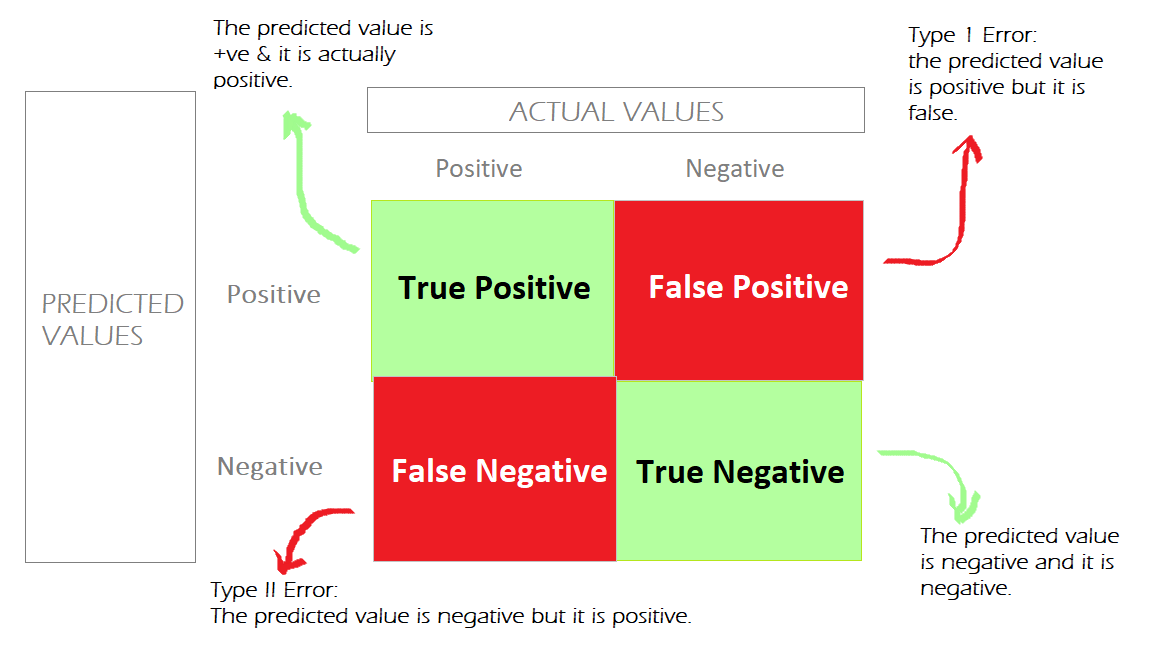

Best model in this split: Random forest
                 precision    recall  f1-score   support

Did not survive       0.79      0.95      0.86       110
       Survived       0.88      0.61      0.72        69

       accuracy                           0.82       179
      macro avg       0.83      0.78      0.79       179
   weighted avg       0.83      0.82      0.81       179



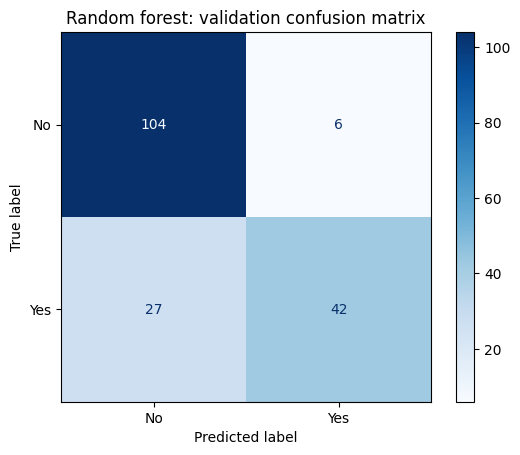

In [ ]:
best_basic_name = results.iloc[0]["Model"]
best_basic_model = fitted_models[best_basic_name]
valid_predictions = best_basic_model.predict(X_valid)
print(f"Best model in this split: {best_basic_name}")
print(classification_report(y_valid, valid_predictions, target_names=["Did not survive", "Survived"]))
ConfusionMatrixDisplay.from_predictions(y_valid, valid_predictions, display_labels=["No", "Yes"], cmap="Blues")
plt.title(f"{best_basic_name}: validation confusion matrix")
plt.show()

## 5. Feature engineering

Feature engineering means creating a more useful feature from the columns we already have. Here we create:

- `FamilySize`: siblings/spouse + parents/children + the passenger.
- `IsAlone`: whether the passenger traveled alone.
- `FarePerPerson`: fare divided by the number of people sharing the ticket.
- `Title`: a short title extracted from the passenger's name (`Mr`, `Miss`, `Mrs`, etc.).
- `Deck`: the first letter of the cabin when known; missing cabins become `Unknown`.

These are hypotheses, not guaranteed truths. We will test whether they help validation and cross-validation scores.


In [ ]:
def add_features(frame):
    data = frame.copy()
    data["FamilySize"] = data["SibSp"] + data["Parch"] + 1
    data["IsAlone"] = (data["FamilySize"] == 1).astype(int)
    data["FarePerPerson"] = data["Fare"] / data["FamilySize"]
    data["Title"] = data["Name"].str.extract(r",\s*([^.]*)\.", expand=False).str.strip()
    common_titles = ["Mr", "Miss", "Mrs", "Master"]
    data["Title"] = data["Title"].where(data["Title"].isin(common_titles), "Rare")
    data["Deck"] = data["Cabin"].fillna("Unknown").str[0]
    return data

train_engineered = add_features(train)
test_engineered = add_features(test)
engineered_features = [
    "Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked",
    "FamilySize", "IsAlone", "FarePerPerson", "Title", "Deck"
]
X_eng = train_engineered[engineered_features]
X_test_eng = test_engineered[engineered_features]
numeric_eng = ["Pclass", "Age", "SibSp", "Parch", "Fare", "FamilySize", "IsAlone", "FarePerPerson"]
categorical_eng = ["Sex", "Embarked", "Title", "Deck"]
preprocessor_eng = ColumnTransformer([
    ("numbers", Pipeline([( "fill_missing", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric_eng),
    ("categories", Pipeline([( "fill_missing", SimpleImputer(strategy="most_frequent")), ("one_hot", OneHotEncoder(handle_unknown="ignore"))]), categorical_eng),
])

X_eng_train, X_eng_valid, y_eng_train, y_eng_valid = train_test_split(
    X_eng, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
engineered_model = Pipeline([
    ("prepare", preprocessor_eng),
    ("model", RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=2, random_state=RANDOM_STATE)),
])
engineered_model.fit(X_eng_train, y_eng_train)
engineered_score = accuracy_score(y_eng_valid, engineered_model.predict(X_eng_valid))
print(f"Engineered random forest validation accuracy: {engineered_score:.3f}")
print("Compare this with the basic random forest above; a new feature is only useful if evaluation supports it.")

Engineered random forest validation accuracy: 0.816
Compare this with the basic random forest above; a new feature is only useful if evaluation supports it.


## 6. Hyperparameter tuning

A **hyperparameter** is a setting we choose before training. For a random forest, examples include:

- `n_estimators`: number of trees.
- `max_depth`: maximum depth of each tree.
- `min_samples_leaf`: minimum rows allowed in a leaf.

`GridSearchCV` tries the combinations we specify and uses cross-validation to select the combination with the best average accuracy. This takes longer than fitting one model, but it is still small enough for this dataset.


In [ ]:
tuning_pipeline = Pipeline([
    ("prepare", preprocessor_eng),
    ("model", RandomForestClassifier(random_state=RANDOM_STATE)),
])
parameter_grid = {
    "model__n_estimators": [100, 300],
    "model__max_depth": [3, 6, None],
    "model__min_samples_leaf": [1, 2, 4],
}
grid_search = GridSearchCV(
    tuning_pipeline, parameter_grid, cv=cv, scoring="accuracy", n_jobs=-1, return_train_score=False
)
grid_search.fit(X_eng, y)
print("Best settings:", grid_search.best_params_)
print(f"Best mean cross-validation accuracy: {grid_search.best_score_:.3f}")
display(pd.DataFrame(grid_search.cv_results_)[["param_model__n_estimators", "param_model__max_depth", "param_model__min_samples_leaf", "mean_test_score"]].sort_values("mean_test_score", ascending=False).head(10))

Best settings: {'model__max_depth': None, 'model__min_samples_leaf': 4, 'model__n_estimators': 100}
Best mean cross-validation accuracy: 0.837


,param_model__n_estimators,param_model__max_depth,param_model__min_samples_leaf,mean_test_score
16,100,None,4,0.837242
8,100,6,2,0.836125
6,100,6,1,0.836125
9,300,6,2,0.836118
7,300,6,1,0.836118
10,100,6,4,0.835001
17,300,None,4,0.835001
15,300,None,2,0.834995
11,300,6,4,0.832760
14,100,None,2,0.829389


### Optional: an ensemble

An **ensemble** combines predictions from multiple models. This example uses soft voting: each model contributes a probability, and the ensemble chooses the class with the highest average probability. It is useful to experiment with, but it is not automatically better. Always keep the validation and cross-validation evidence.


In [ ]:
ensemble = VotingClassifier(
    estimators=[
        ("logistic", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
        ("forest", RandomForestClassifier(n_estimators=300, max_depth=6, random_state=RANDOM_STATE)),
        ("svm", SVC(probability=True, C=1.0, random_state=RANDOM_STATE)),
    ],
    voting="soft",
)
ensemble_pipeline = Pipeline([( "prepare", preprocessor_eng), ("model", ensemble)])
ensemble_scores = cross_val_score(ensemble_pipeline, X_eng, y, cv=cv, scoring="accuracy")
print(f"Ensemble mean CV accuracy: {ensemble_scores.mean():.3f}")
print("Use the tuned forest if it is at least as good and is easier to explain.")

Ensemble mean CV accuracy: 0.833
Use the tuned forest if it is at least as good and is easier to explain.


## 7. Train the final model and create a submission

We have finished experimenting. The tuned model has not seen the competition test answers, and we should not use the Kaggle leaderboard as a substitute for careful validation. Now we fit the selected model on **all** labeled training rows, predict the test rows, and create the exact two-column format Kaggle expects.


In [ ]:
final_model = grid_search.best_estimator_
final_model.fit(X_eng, y)
test_predictions = final_model.predict(X_test_eng).astype(int)

submission = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Survived": test_predictions,
})
submission_path = Path("submission.csv")
submission.to_csv(submission_path, index=False)

assert list(submission.columns) == ["PassengerId", "Survived"]
assert len(submission) == len(test)
assert set(submission["Survived"].unique()).issubset({0, 1})
print(f"Saved {submission_path.resolve()}")
display(submission.head())

Saved /content/submission.csv


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


### Submit on Kaggle

1. In the notebook's **Output** panel, find `submission.csv` and download it, or use the file created in the notebook.
2. Return to the Titanic competition page.
3. Choose **Submit Predictions**.
4. Upload `submission.csv`.
5. Record the public leaderboard accuracy.

The leaderboard score may differ from validation accuracy because it is evaluated on different unseen rows. A small score change does not prove that a model is truly better.


## 8. Workshop reflection and next experiments

Write down your answers before changing the code:

1. Which model had the best mean cross-validation accuracy? Was it also the best on your one validation split?
2. Which kinds of errors appeared in the confusion matrix?
3. Did feature engineering help? Which engineered feature seems most plausible?
4. Did tuning improve the score enough to justify the extra complexity?
5. Why is it invalid to train on `test.csv`'s hidden answers?

### Try one controlled experiment

Change **one thing at a time**, rerun the evaluation, and record the result:

- Remove `Title` or `Deck` and compare.
- Try a smaller or larger `max_depth`.
- Add a `FamilyGroup` feature such as `SibSp + Parch`.
- Compare accuracy with a different scoring metric, such as precision or recall.

This is the core ML loop: **hypothesis → change → train → evaluate → interpret**.


## Key takeaways

- Machine learning is a loop of data, algorithms, and evaluation.
- A model that scores well on its training data may simply be overfitting.
- Preprocessing belongs inside a pipeline so that validation and test data are treated consistently.
- Cross-validation gives a more stable estimate than one random split.
- Hyperparameter tuning searches settings; it does not replace good features or careful evaluation.
- The best model is the one supported by evidence and appropriate for the goal—not necessarily the most complicated one.
